In [1]:
import pandas as pd
import numpy as np

# Load dataset
df = pd.read_csv("data/raw/creditcard.csv")

# Basic structure
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

# Preview first rows
df.head()

Dataset shape: (284807, 31)

Column names:
['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class']


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [4]:
# Check for missing values
missing_values = df.isnull().sum()

print("Missing values per column:")
print(missing_values[missing_values > 0])


Missing values per column:
Series([], dtype: int64)


In [5]:
# Check duplicated rows
num_duplicates = df.duplicated().sum()

print(f"Number of duplicated rows: {num_duplicates}")


Number of duplicated rows: 1081


In [7]:
# Remove exact duplicate rows
df_clean = df.drop_duplicates().reset_index(drop=True)

print("Original dataset shape:", df.shape)
print("Cleaned dataset shape :", df_clean.shape)
print("Duplicates removed     :", df.shape[0] - df_clean.shape[0])

Original dataset shape: (284807, 31)
Cleaned dataset shape : (283726, 31)
Duplicates removed     : 1081


In [8]:
assert df_clean.duplicated().sum() == 0, "Duplicates still exist!"
print("Duplicate check passed ✅")


Duplicate check passed ✅


In [9]:
# Class counts
class_counts = df_clean['Class'].value_counts()

# Class percentages
class_percentages = df_clean['Class'].value_counts(normalize=True) * 100

print("Class counts:")
print(class_counts)

print("\nClass percentages:")
print(class_percentages)


Class counts:
Class
0    283253
1       473
Name: count, dtype: int64

Class percentages:
Class
0    99.83329
1     0.16671
Name: proportion, dtype: float64


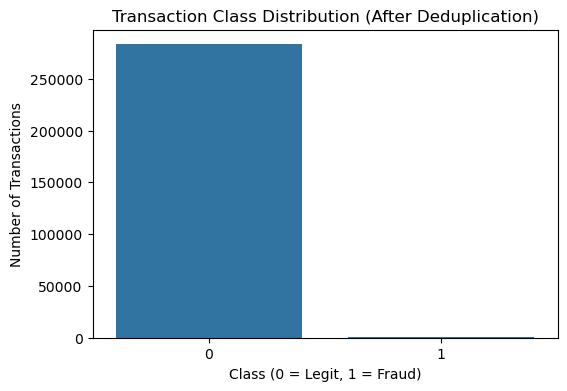

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(6, 4))
sns.countplot(x='Class', data=df_clean)
plt.title("Transaction Class Distribution (After Deduplication)")
plt.xlabel("Class (0 = Legit, 1 = Fraud)")
plt.ylabel("Number of Transactions")
plt.show()


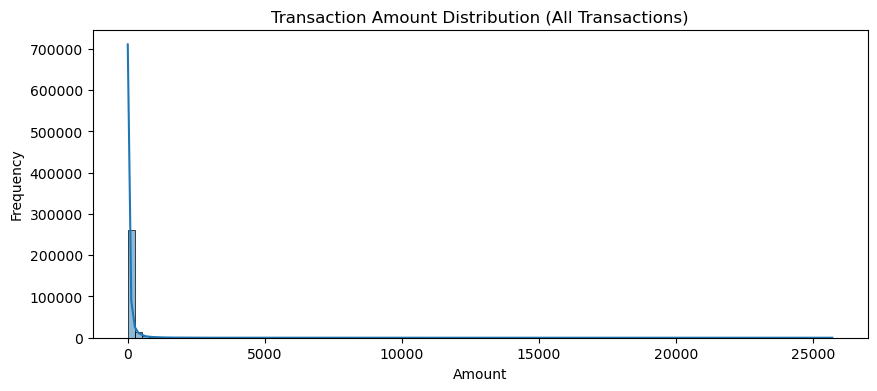

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 4))
sns.histplot(df_clean['Amount'], bins=100, kde=True)
plt.title("Transaction Amount Distribution (All Transactions)")
plt.xlabel("Amount")
plt.ylabel("Frequency")
plt.show()


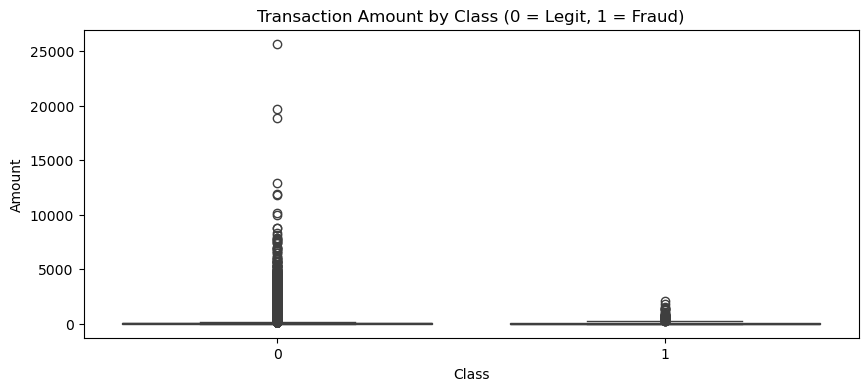

In [12]:
plt.figure(figsize=(10, 4))
sns.boxplot(x='Class', y='Amount', data=df_clean)
plt.title("Transaction Amount by Class (0 = Legit, 1 = Fraud)")
plt.xlabel("Class")
plt.ylabel("Amount")
plt.show()


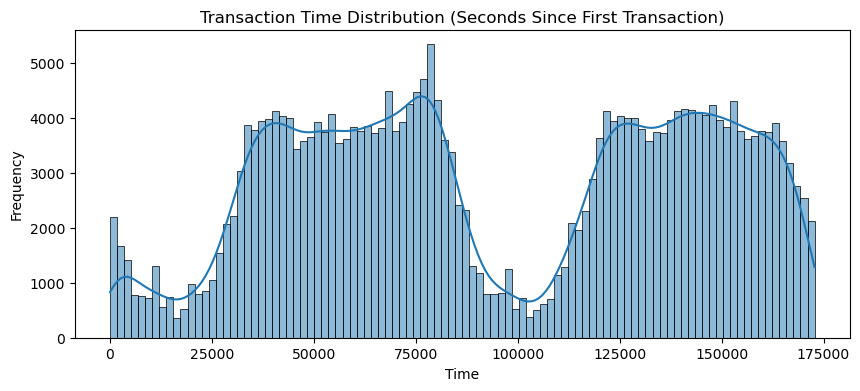

In [13]:
plt.figure(figsize=(10, 4))
sns.histplot(df_clean['Time'], bins=100, kde=True)
plt.title("Transaction Time Distribution (Seconds Since First Transaction)")
plt.xlabel("Time")
plt.ylabel("Frequency")
plt.show()


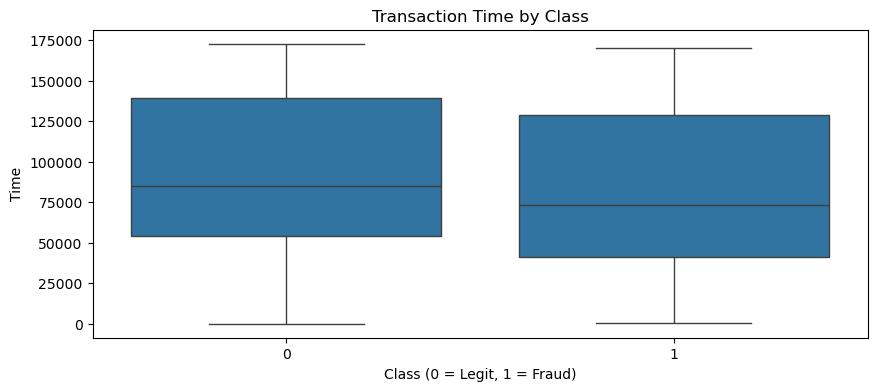

In [14]:
plt.figure(figsize=(10, 4))
sns.boxplot(x='Class', y='Time', data=df_clean)
plt.title("Transaction Time by Class")
plt.xlabel("Class (0 = Legit, 1 = Fraud)")
plt.ylabel("Time")
plt.show()


In [ ]:
from sklearn.model_selection import train_test_split

# Separate features and target
X = df_clean.drop(columns=['Class'])
y = df_clean['Class']

# Create Streamlit test set (exactly 10 rows)
X_streamlit, X_remaining, y_streamlit, y_remaining = train_test_split(
    X,
    y,
    test_size=len(df_clean) - 10,
    stratify=y,
    random_state=42
)

print("Streamlit test set shape:", X_streamlit.shape)
print("Class distribution in Streamlit test set:")
print(y_streamlit.value_counts())


Streamlit test set shape: (10, 30)
Class distribution in Streamlit test set:
Class
0    10
Name: count, dtype: int64


In [19]:
# Combine features and label
streamlit_test_df = X_streamlit.copy()
streamlit_test_df['Class'] = y_streamlit.values

# Save to CSV for Streamlit app
streamlit_test_df.to_csv(
    "data/processed/streamlit_test_data.csv",
    index=False
)

print("Streamlit test data saved to:")
print("data/processed/streamlit_test_data.csv")


OSError: Cannot save file into a non-existent directory: 'data\processed'